In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

#Load dataset
df = pd.read_csv("../data/institution_type_large.csv")

In [3]:
#Basic Information
print("📏 Dataset shape (rows, columns):", df.shape)

print("\n🧾 Column names and data types:")
print(df.dtypes)

print("\n🔍 First 5 rows:")
display(df.head())

📏 Dataset shape (rows, columns): (32400, 8)

🧾 Column names and data types:
Yil                     int64
Ay                      int64
Kurum Turu             object
Muracaat Sayisi         int64
Kronik Hasta Orani    float64
Saglik Enflasyonu     float64
Kisi Basi Maliyet     float64
Toplam Harcama        float64
dtype: object

🔍 First 5 rows:


,Yil,Ay,Kurum Turu,Muracaat Sayisi,Kronik Hasta Orani,Saglik Enflasyonu,Kisi Basi Maliyet,Toplam Harcama
0,2015,1,Devlet,194613,0.16,0.08,353.98,68889109.74
1,2015,1,Devlet,196555,0.30,0.08,416.05,81776707.75
2,2015,1,Devlet,146339,0.18,0.08,431.44,63136498.16
3,2015,1,Devlet,127862,0.19,0.08,395.91,50621844.42
4,2015,1,Devlet,204725,0.19,0.08,359.27,73551550.75


In [4]:
#Missing values
print("🧩 Missing value count per column:")
display(df.isnull().sum())

print("\n📊 Missing value percentage:")
display((df.isnull().sum() / len(df) * 100).round(2).astype(str) + '%')

🧩 Missing value count per column:


Yil                   0
Ay                    0
Kurum Turu            0
Muracaat Sayisi       0
Kronik Hasta Orani    0
Saglik Enflasyonu     0
Kisi Basi Maliyet     0
Toplam Harcama        0
dtype: int64


📊 Missing value percentage:


Yil                   0.0%
Ay                    0.0%
Kurum Turu            0.0%
Muracaat Sayisi       0.0%
Kronik Hasta Orani    0.0%
Saglik Enflasyonu     0.0%
Kisi Basi Maliyet     0.0%
Toplam Harcama        0.0%
dtype: object

In [5]:
#Descriptive statistics
print("📊 Descriptive statistics:")
display(df.describe().T)

📊 Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Yil,32400.0,2.019000e+03,2.582029e+00,2015.00,2017.00,2.019000e+03,2.021000e+03,2.023000e+03
Ay,32400.0,6.500000e+00,3.452106e+00,1.00,3.75,6.500000e+00,9.250000e+00,1.200000e+01
Muracaat Sayisi,32400.0,1.496732e+05,3.410776e+04,26797.00,125887.50,1.481885e+05,1.719142e+05,3.239530e+05
Kronik Hasta Orani,32400.0,1.800892e-01,4.019799e-02,0.05,0.15,1.800000e-01,2.100000e-01,3.400000e-01
Saglik Enflasyonu,32400.0,1.600000e-01,4.944209e-02,0.08,0.12,1.700000e-01,1.900000e-01,2.400000e-01
Kisi Basi Maliyet,32400.0,3.490261e+02,7.100544e+01,89.31,299.64,3.453750e+02,3.946925e+02,6.879300e+02
Toplam Harcama,32400.0,5.265119e+07,1.761637e+07,9423870.95,39886021.74,5.050018e+07,6.296080e+07,1.559857e+08


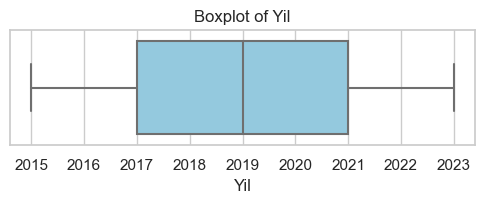

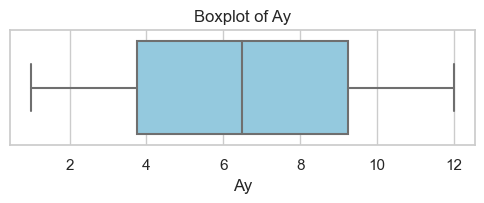

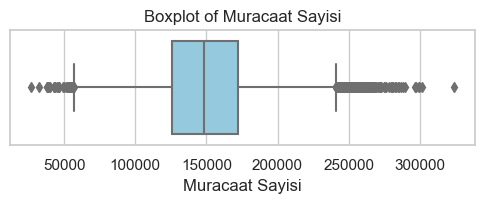

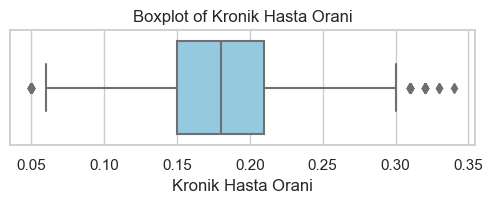

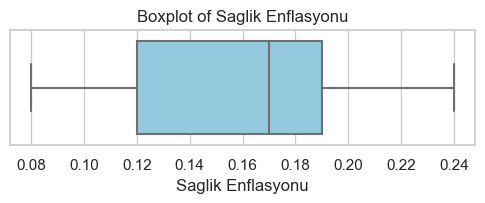

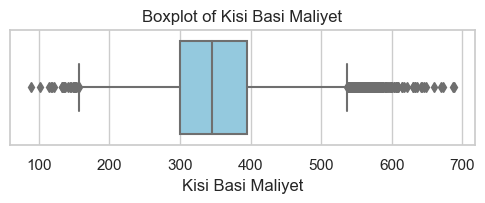

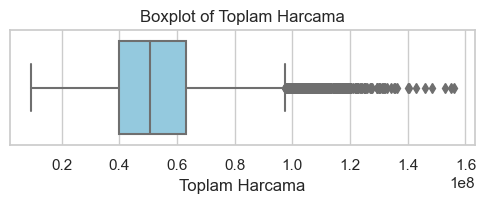

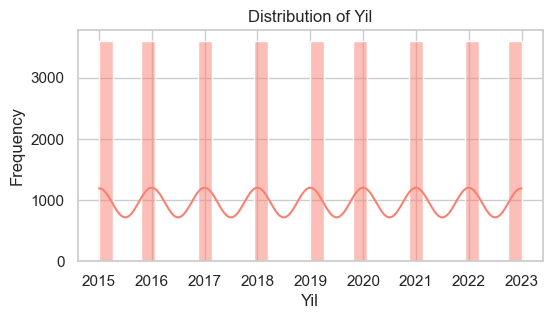

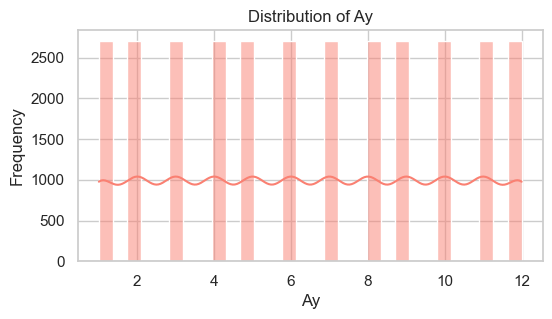

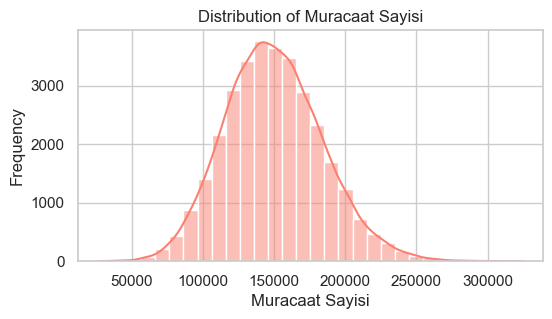

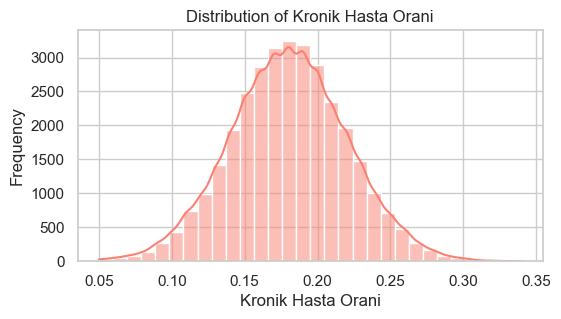

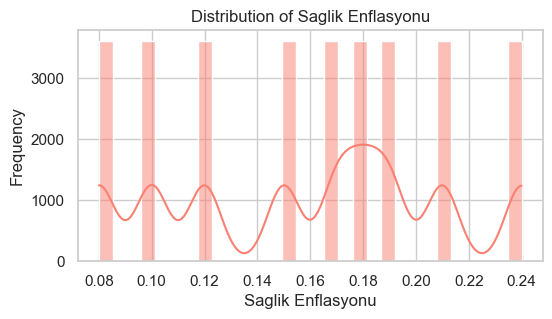

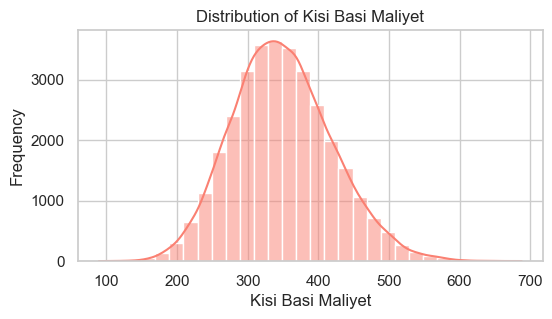

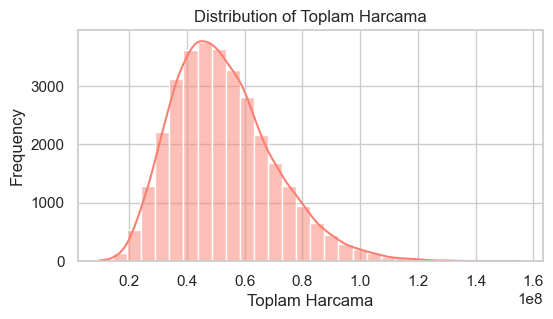

In [7]:
#Outlier detection and distribution for numerical columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Boxplots
for col in numeric_cols:
    plt.figure(figsize=(6, 1.5))
    sns.boxplot(x=df[col], color="skyblue")
    plt.title(f"Boxplot of {col}")
    plt.show()

# Histograms
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.histplot(df[col], kde=True, bins=30, color="salmon")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

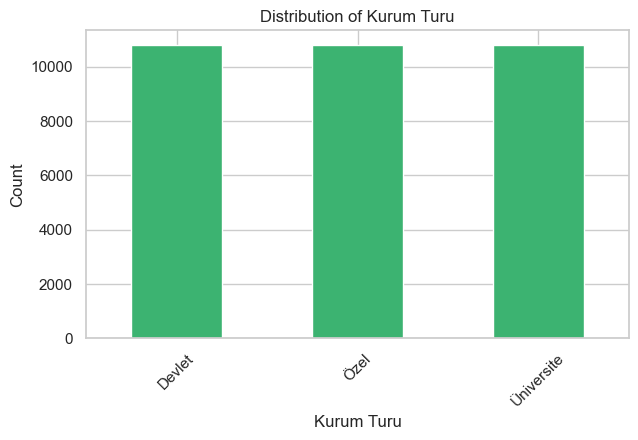

In [8]:
#Categorical column distributions
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

for col in categorical_cols:
    plt.figure(figsize=(7, 4))
    df[col].value_counts().plot(kind='bar', color='mediumseagreen')
    plt.title(f"Distribution of {col}")
    plt.ylabel("Count")
    plt.xlabel(col)
    plt.xticks(rotation=45)
    plt.show()

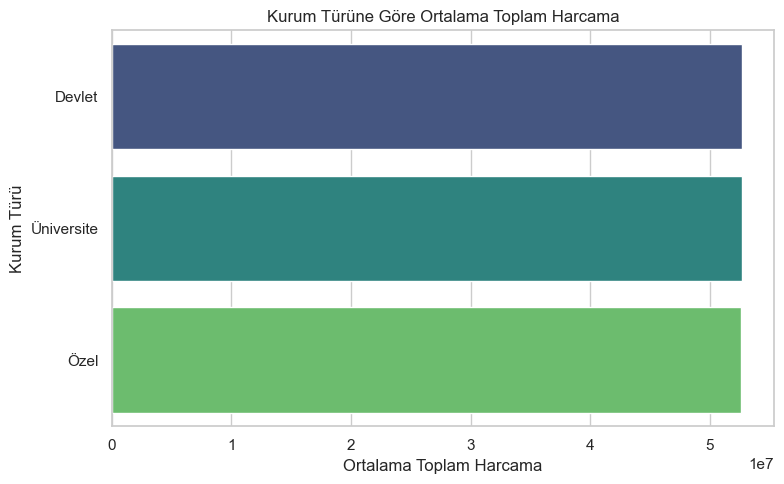

In [10]:
#Average spending by Institution Type
avg_per_institution = df.groupby('Kurum Turu')['Toplam Harcama'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=avg_per_institution.values, y=avg_per_institution.index, palette="viridis")
plt.title("Kurum Türüne Göre Ortalama Toplam Harcama")
plt.xlabel("Ortalama Toplam Harcama")
plt.ylabel("Kurum Türü")
plt.tight_layout()
plt.show()

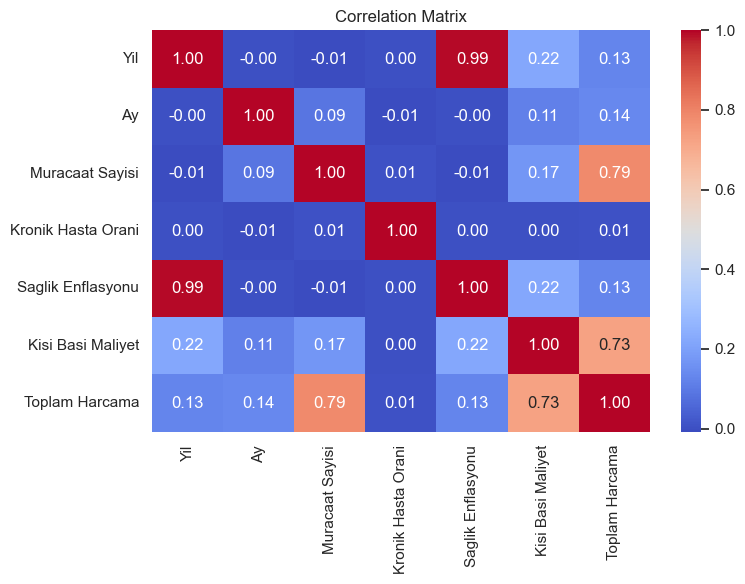

In [11]:
#Correlation matrix (for numeric columns only)
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(8, 6))
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()